# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')

# Reading Data

In [3]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\463\\Data\\Regression_NewLesion.csv")

In [4]:
df.columns

Index(['Unnamed: 0', 'SUBJID', 'LBSTRESN', 'VISITDY_x', 'LBTEST_Albumin',
       'LBTEST_Alkaline Phosphatase', 'LBTEST_Carcinoembryonic Antigen',
       'LBTEST_Creatinine', 'LBTEST_Hemoglobin',
       'LBTEST_Lactate Dehydrogenase', 'LBTEST_Platelets',
       'LBTEST_White Blood Cells', 'LBBASE_N', 'LBBASE_Y', 'LSSITE', 'LSCAT',
       'min_VISITDY', 'min_LSSLD', 'max_VISITDY', 'max_LSSLD', 'LSSLD_Diff',
       'Percentage_LSSLD_Change', 'VISITDY_y', 'LSNEWANY', 'WEIGHT', 'VISITDY',
       'RSTRESP_Progressive disease', 'RSTRESP_Stable disease',
       'RSTRESP_Unknown', 'RSNTRESP_Progressive disease',
       'RSNTRESP_Stable disease', 'RSNTRESP_Unknown', 'TRT', 'ATRT', 'SXANY',
       'DTHDYX', 'DTHX', 'PFSDYCR', 'PFSCR', 'DIAGMONS', 'AGE', 'SEX',
       'B_WEIGHT', 'RACE', 'B_ECOG', 'HISSUBTY', 'DIAGTYPE', 'AESEVCD',
       'AEPT_ACNE', 'AEPT_CELLULITIS', 'AEPT_CONTUSION', 'AEPT_DERMATITIS',
       'AEPT_DERMATITIS ACNEIFORM', 'AEPT_DERMATITIS ALLERGIC',
       'AEPT_DRY SKIN', 'AE

In [5]:
df.shape

(10070, 100)

In [6]:
df.head()

,Unnamed: 0,SUBJID,LBSTRESN,VISITDY_x,LBTEST_Albumin,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,...,AEPT_SKIN FISSURES,AEPT_SKIN INDURATION,AEPT_SKIN IRRITATION,AEPT_SKIN LESION,AEPT_SKIN MACERATION,AEPT_SKIN TOXICITY,AEPT_SKIN ULCER,AEPT_TELANGIECTASIA,AECONT_N,AECONT_Y
0,244,1,199.395854,23.604167,2,2,2,2,2,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
1,245,1,199.395854,23.604167,2,2,2,2,2,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
2,246,1,199.395854,23.604167,2,2,2,2,2,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
3,247,1,199.395854,23.604167,2,2,2,2,2,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
4,248,1,199.395854,23.604167,2,2,2,2,2,2,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0


In [7]:
df['LSNEWANY'].unique()

array(['N', 'Y'], dtype=object)

# Feature Selection by Random Forest

In [15]:
df1=df

In [17]:
df1['LSNEWANY'] = df1['LSNEWANY'].astype('category').cat.codes

In [19]:
df1 = pd.get_dummies(df1, drop_first=True)

In [21]:
# Separate features and target
X = df1.drop('LSNEWANY', axis=1)
y = df1['LSNEWANY']

In [23]:
# Separate features and target
X = df1.drop('LSNEWANY', axis=1)
y = df1['LSNEWANY']

In [25]:
# Train a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [26]:
importances = rf.feature_importances_

In [27]:
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [28]:
feature_importances_df.head(40)

,Feature,Importance
20,VISITDY_y,0.592742
0,Unnamed: 0,0.236371
14,min_VISITDY,0.017236
31,PFSDYCR,0.012495
3,VISITDY_x,0.010467
16,max_VISITDY,0.008094
22,VISITDY,0.007701
27,RSNTRESP_Stable disease,0.006485
18,LSSLD_Diff,0.006084
23,RSTRESP_Progressive disease,0.005762


# Forming New Datasets

In [34]:
df=df[['SUBJID','LSNEWANY','LSSITE','PFSDYCR','RSNTRESP_Stable disease','RSTRESP_Progressive disease', 'DIAGMONS', 'DTHDYX', 'AECONT_N', 'LBSTRESN','AEPT_EXFOLIATIVE RASH','AESEVCD','RSNTRESP_Progressive disease','AECONT_Y','AEPT_ERYTHEMA','AEPT_PRURITUS','AEPT_DERMATITIS ACNEIFORM','AEPT_SKIN ULCER']]
df.shape

(10070, 18)

In [36]:
df.head()

,SUBJID,LSNEWANY,LSSITE,PFSDYCR,RSNTRESP_Stable disease,RSTRESP_Progressive disease,DIAGMONS,DTHDYX,AECONT_N,LBSTRESN,AEPT_EXFOLIATIVE RASH,AESEVCD,RSNTRESP_Progressive disease,AECONT_Y,AEPT_ERYTHEMA,AEPT_PRURITUS,AEPT_DERMATITIS ACNEIFORM,AEPT_SKIN ULCER
0,1,0,Liver,84.0,3,1,54.983607,218.0,3.0,199.395854,0.0,3.0,9,0.0,0.0,0.0,0.0,0.0
1,1,1,Liver,84.0,3,1,54.983607,218.0,3.0,199.395854,0.0,3.0,9,0.0,0.0,0.0,0.0,0.0
2,1,0,Liver,84.0,3,1,54.983607,218.0,3.0,199.395854,0.0,3.0,9,0.0,0.0,0.0,0.0,0.0
3,1,1,Liver,84.0,3,1,54.983607,218.0,3.0,199.395854,0.0,3.0,9,0.0,0.0,0.0,0.0,0.0
4,1,0,Liver,84.0,3,1,54.983607,218.0,3.0,199.395854,0.0,3.0,9,0.0,0.0,0.0,0.0,0.0


In [38]:
dfnew=df.drop_duplicates(keep='first')
dfnew.shape

(509, 18)

In [40]:
result1=dfnew

# Logistic Regression

In [43]:
result1.shape

(509, 18)

In [45]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [47]:
result1.fillna(0, inplace=True)

In [49]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes
result1['LSSITE'] = result1['LSSITE'].astype('category').cat.codes

In [51]:
X=result1[['LSSITE','PFSDYCR','RSNTRESP_Stable disease', 'DIAGMONS', 'DTHDYX', 'LBSTRESN','AEPT_EXFOLIATIVE RASH','AESEVCD','AECONT_Y','AEPT_ERYTHEMA','AEPT_PRURITUS','AEPT_DERMATITIS ACNEIFORM','AEPT_SKIN ULCER']]
y=result1[['LSNEWANY']]

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [55]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [57]:
model11= LogisticRegression()

In [59]:
model11.fit(X_train_scaled, y_train)

LogisticRegression()

In [61]:
y_pred = model11.predict(X_test_scaled)

In [63]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.4314


In [65]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[ 2 56]
 [ 2 42]]


In [67]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.03      0.06        58
           1       0.43      0.95      0.59        44

    accuracy                           0.43       102
   macro avg       0.46      0.49      0.33       102
weighted avg       0.47      0.43      0.29       102



In [69]:
y_train_pred = model11.predict(X_train_scaled)

y_test_pred = model11.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.5651
Test Accuracy: 0.4314


# Feature Importance

                      Feature  Importance
8                    AECONT_Y    0.127813
10              AEPT_PRURITUS    0.119766
7                     AESEVCD   -0.096289
4                      DTHDYX    0.093697
2     RSNTRESP_Stable disease    0.066296
3                    DIAGMONS    0.055174
5                    LBSTRESN   -0.051467
12            AEPT_SKIN ULCER   -0.045019
9               AEPT_ERYTHEMA   -0.036192
6       AEPT_EXFOLIATIVE RASH   -0.030768
1                     PFSDYCR   -0.022348
0                      LSSITE    0.007104
11  AEPT_DERMATITIS ACNEIFORM   -0.004582


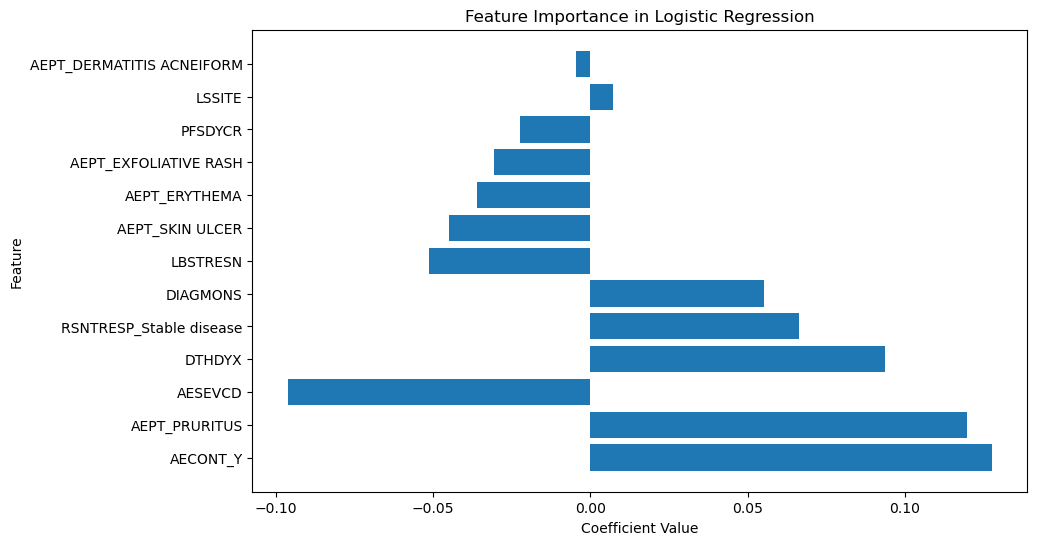

In [72]:
if len(model11.coef_) == 1:
    coefficients = model11.coef_[0]
else:
    coefficients = np.mean(model11.coef_, axis=0)

if len(coefficients) != len(X.columns):
    print("Mismatch between number of coefficients and number of features!")
else:
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    })

    importance_df['Abs_Importance'] = np.abs(importance_df['Importance'])
    importance_df = importance_df.sort_values(by='Abs_Importance', ascending=False)

    print(importance_df[['Feature', 'Importance']])

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'])
    plt.xlabel('Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Feature Importance in Logistic Regression')
    plt.show()

# XGBoost Regression

!pip install xgboost

In [76]:
import xgboost as xgb

In [78]:
features=result1[['LSSITE','PFSDYCR','RSNTRESP_Stable disease', 'DIAGMONS', 'DTHDYX', 'LBSTRESN','AEPT_EXFOLIATIVE RASH','AESEVCD','AECONT_Y','AEPT_ERYTHEMA','AEPT_PRURITUS','AEPT_DERMATITIS ACNEIFORM','AEPT_SKIN ULCER']]
target=result1[['LSNEWANY']]

In [80]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.2, random_state=42)

In [84]:
# Initialize and fit the XGBoost model
model12 = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model12.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [86]:
y_pred = model12.predict(X_test)

In [88]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.1765
Confusion Matrix:
[[ 4 54]
 [30 14]]
Classification Report:
              precision    recall  f1-score   support

           0       0.12      0.07      0.09        58
           1       0.21      0.32      0.25        44

    accuracy                           0.18       102
   macro avg       0.16      0.19      0.17       102
weighted avg       0.16      0.18      0.16       102



# Feature Importance

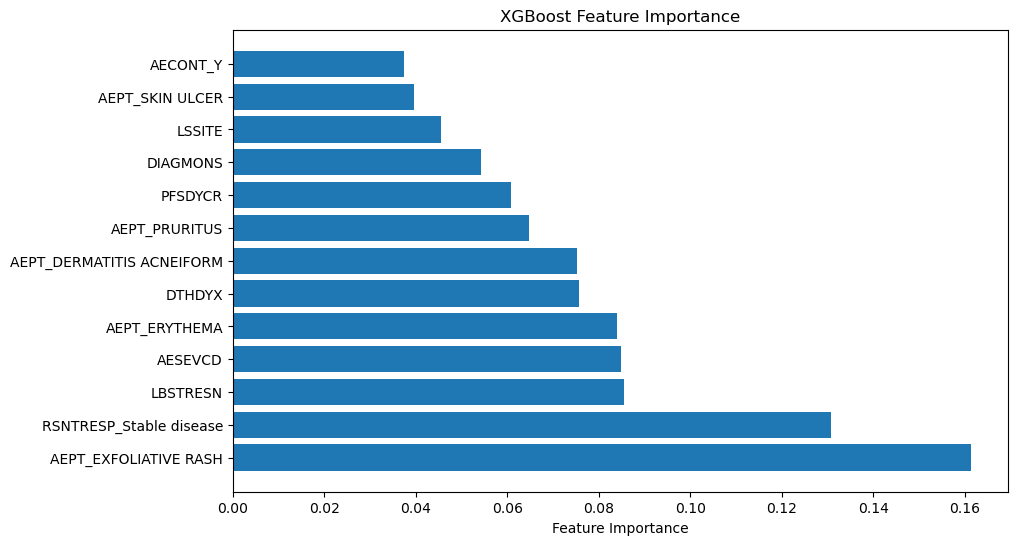

In [93]:
importance = model12.feature_importances_
# Sort feature importance values in descending order
sorted_idx = np.argsort(importance)[::-1]
sorted_importance = importance[sorted_idx]

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(range(len(sorted_importance)), sorted_importance, align='center')
plt.yticks(range(len(sorted_idx)), features.columns[sorted_idx])
plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance")
plt.show()

# Regression with Linear,Decision Tree,Random Forest,Gadient Boosting,Support Vector and Neural Network

In [95]:
features=result1[['LSSITE','PFSDYCR','RSNTRESP_Stable disease', 'DIAGMONS', 'DTHDYX', 'LBSTRESN','AEPT_EXFOLIATIVE RASH','AESEVCD','AECONT_Y','AEPT_ERYTHEMA','AEPT_PRURITUS','AEPT_DERMATITIS ACNEIFORM','AEPT_SKIN ULCER']]
target=result1[['LSNEWANY']]

In [97]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR()),
    "Neural Network": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate Mean Squared Error and R² Score
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} - Mean Squared Error: {mse}, R² Score: {r2}")


Linear Regression - Mean Squared Error: 0.26391323084893226, R² Score: -0.07592212137628973
Decision Tree - Mean Squared Error: 0.7843137254901961, R² Score: -2.1974921630094046
Random Forest - Mean Squared Error: 0.5373364557837024, R² Score: -1.1906146104912385
Gradient Boosting - Mean Squared Error: 0.4327365290086647, R² Score: -0.7641813666951993
Support Vector Regression - Mean Squared Error: 0.4632626181918337, R² Score: -0.8886302036315981
Neural Network - Mean Squared Error: 0.3076019898921284, R² Score: -0.254032563807878


# ROC and AUC

In [100]:
X, y = make_classification(n_samples=1000, n_features=20, 
                           n_informative=2, n_redundant=10, 
                           random_state=42)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [102]:
# Train a model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict probabilities
y_score = model.predict_proba(X_test)[:, 1]

# Compute ROC curve and ROC AUC
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

In [104]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.84


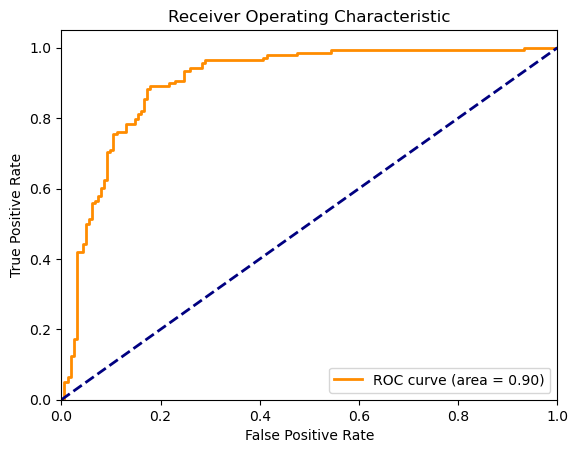

In [106]:
# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()